In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy import ndimage


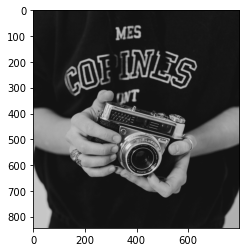

In [2]:

def rgb2gray(rgb):
    return np.dot(rgb[...,:3], [0.299, 0.587, 0.144])

img = mpimg.imread('res/camera.jpg')

gray = rgb2gray(img)

plt.imshow(gray, cmap = plt.get_cmap('gray'))
plt.show()

(844, 800)


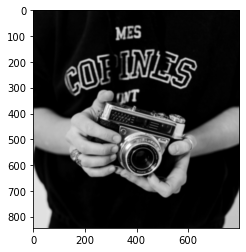

In [3]:
camera_blurred = ndimage.gaussian_filter(gray, sigma=1.4)
print(camera_blurred.shape)
plt.imshow(camera_blurred, cmap = plt.get_cmap('gray'))
plt.show()

In [4]:
def sobelFilter(img, filterDirection):
    if( filterDirection == 'x'):
        Gx = np.array([[-1, 0, +1], [-2, 0, +2], [-1, 0, +1]])
        convolved = ndimage.convolve(img, Gx)
    elif( filterDirection == 'y'):
        Gy = np.array([[-1, -2, -1], [0, 0, 0], [+1, +2, +1]])
        convolved = ndimage.convolve(img, Gy)
    return convolved

In [5]:
# Normalize the pixel to <= 1
def Normalize(img):
    img = img/np.max(img)
    return img

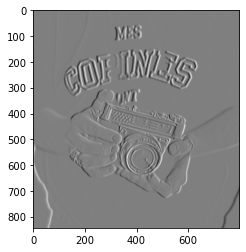

In [6]:
# Apply Sobel filter in X - direction (Gx)
vertical_edge = sobelFilter(camera_blurred, 'x')
vertical_edge = Normalize(vertical_edge)
plt.imshow(vertical_edge, cmap = plt.get_cmap('gray'))
plt.show()

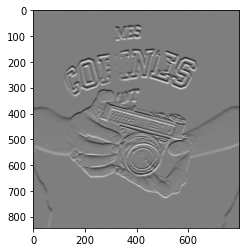

In [7]:
# Apply Sobel filter in Y - direction (Gy)
horizontal_edge = sobelFilter(camera_blurred, 'y')
horizontal_edge = Normalize(horizontal_edge)
plt.imshow(horizontal_edge, cmap = plt.get_cmap('gray'))
plt.show()

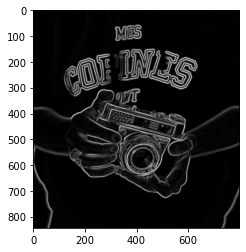

In [8]:
# Calculate the magnitude G = sqrt(gx^2 + gy^2)
magnitude = np.hypot(horizontal_edge, vertical_edge)
plt.imshow(magnitude, cmap= plt.get_cmap('gray'))
plt.show()

In [27]:
# Calculate angle
# theta = arctan(Gy / Gx)
# arctan2 return arctan(Gy / Gx) randian in between -pi to pi and is converted to degree 
theta = np.degrees(np.arctan2( horizontal_edge, vertical_edge ))


False

In [30]:
# Perform Non-Maximum supression without interpolation
def NonMaxSupWithoutInterpol(g_mag, grad):
    NMS = np.zeros(g_mag.shape)
    for i in range(1, g_mag.shape[0] - 1):
        for j in range(1, g_mag.shape[1] - 1):
            if( (grad[i, j] >= -22.5 and grad[i, j] <= 22.5) or (grad[i, j] >= 157.5 and grad[i, j] <= -157.5) ):
                if( g_mag[i, j] > g_mag[i, j+1] and g_mag[i, j] > g_mag[i, j-1] ):
                    NMS[i, j] = g_mag[i, j]
                else:
                    # Set black
                    NMS[i, j] = 0
            elif( (grad[i, j] >= 22.5 and grad[i, j] <= 67.5) or (grad[i, j] >= -157.5 and grad[i, j] <= -112.5) ):
                if( g_mag[i, j] > g_mag[i-1, j+1] and g_mag[i, j] > g_mag[i+1, j-1] ):
                    NMS[i, j] = g_mag[i, j]
                else:
                    NMS[i, j] = 0
            elif( (grad[i, j] >= 67.5 and grad[i, j] <= 112.5) or (grad[i, j] >= -112.5 and grad[i, j] <= -67.5) ):
                if( g_mag[i, j] > g_mag[i-1, j] and g_mag[i, j] > g_mag[i+1, j] ):
                    NMS[i, j] = g_mag[i, j]
                else:
                    NMS[i, j] = 0
            elif( (grad[i, j] >= 112.5 and grad[i, j] <= 157.5) or (grad[i, j] >= -67.5 and grad[i, j] <= -22.5) ):
                if( g_mag[i, j] > g_mag[i-1, j-1] and g_mag[i, j] > g_mag[i+1, j+1] ):
                    NMS[i, j] = g_mag[i, j]
                else:
                    NMS[i, j] = 0
    return NMS



<function matplotlib.pyplot.show(close=None, block=None)>

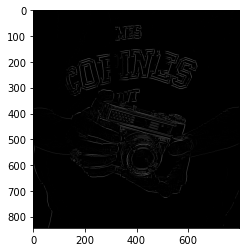

In [32]:
NMS = NonMaxSupWithoutInterpol(magnitude, theta)
plt.imshow(NMS, cmap = plt.get_cmap('gray'))
plt.show

In [ ]:
# NMS with interpolation
def NonMaxSuppressionWithInterpol():
    NMS = np.zeros(g_mag.shape)

    for i in range(1, g_mag.shape[0] - 1):
        for i in range(1, g_mag[1] - 1):
            if( (g_mag[i, j] >= 0 and g_mag[i, j] < 45) or (g_mag[i, j] >= 180 and g_mag[i, j] < -135) ):
                y_bot = np.array( [ g_mag[i, j+1], g_mag[i, j1] ] )
                y_top = np.array( [ g_mag[i, j-1], g_mag[i-1,j-1] ] )
                x_est = np.absolute( g_y[i, j] / g_mag[i, j] )
                
